In [307]:
import gzip
import random
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import defaultdict
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, accuracy_score


In [308]:
def readGz(path):
    for l in gzip.open(path, 'rt'):
        yield eval(l)

def readCSV(path):
    f = gzip.open(path, 'rt')
    f.readline()
    for l in f:
        yield l.strip().split(',')

In [309]:
allRatings = [(u, b, int(r)) for u, b, r in readCSV("train_Interactions.csv.gz")]

# Prepare for 10-fold CV - keep all data together
allBooks = list({b for _, b, _ in allRatings})
totalRatings = len(allRatings)
foldSize = totalRatings // 10


In [310]:
# Helper function to build data structures from training data
def build_data_structures(ratingsTrain):
    ratingsPerUser = defaultdict(list)
    ratingsPerItem = defaultdict(list)
    userBooks = defaultdict(set)
    bookUsers = defaultdict(set)
    
    for u, b, r in ratingsTrain:
        ratingsPerUser[u].append((b, r))
        ratingsPerItem[b].append((u, r))
        userBooks[u].add(b)
        bookUsers[b].add(u)
    
    return ratingsPerUser, ratingsPerItem, userBooks, bookUsers

# Helper function to compute book and user counts
def compute_counts(ratingsTrain):
    bookCount = defaultdict(int)
    userCount = defaultdict(int)
    for user, book, _ in ratingsTrain:
        bookCount[book] += 1
        userCount[user] += 1
    return bookCount, userCount

# Helper function to create validation set for a fold
def create_validation_set(ratingsValid, userBooks_train):
    readValid = [(u, b, 1) for u, b, _ in ratingsValid]
    notRead = []
    for u, _, _ in readValid:
        while True:
            b_neg = random.choice(allBooks)
            if b_neg not in userBooks_train[u]:
                notRead.append((u, b_neg, 0))
                break
    return readValid + notRead

In [311]:
def build_popular_books(bookCount, totalRead, threshold):
    mostPopular = [(bookCount[x], x) for x in bookCount]
    mostPopular.sort()
    mostPopular.reverse()
    
    count = 0
    popular = set()
    for ic, i in mostPopular:
        count += ic
        popular.add(i)
        if count > totalRead * threshold:
            break
    return popular

def build_active_users(userCount, totalRead, threshold):
    mostActive = [(userCount[x], x) for x in userCount]
    mostActive.sort()
    mostActive.reverse()
    
    count = 0
    active = set()
    for ic, i in mostActive:
        count += ic
        active.add(i)
        if count > totalRead * threshold:
            break
    return active

In [312]:
def Jaccard(s1, s2):
    intersection = len(s1 & s2)
    if intersection == 0:
        return 0.0
    union = len(s1 | s2)
    return intersection / union

def predictRead(u, b, userBooks, bookUsers, popularBooks, activeUsers, simThreshold):
    if u not in userBooks or not userBooks[u]:
        return int(b in popularBooks)

    if b not in bookUsers or not bookUsers[b]:
        return int(u in activeUsers)
    
    book_b_users = bookUsers[b]
    if not book_b_users:
        return int(b in popularBooks)
    
    book_b_size = len(book_b_users)
    maxSim = 0
    
    # Early exit optimization: if we find a high similarity, return immediately
    for bp in userBooks[u]:
        if bp not in bookUsers:
            continue
            
        book_bp_users = bookUsers[bp]
        if not book_bp_users:
            continue
        
        # Optimize: use smaller set for intersection (faster)
        if book_b_size < len(book_bp_users):
            intersection = len(book_b_users & book_bp_users)
        else:
            intersection = len(book_bp_users & book_b_users)
            
        if intersection == 0:
            continue
        
        # Quick pre-check: if intersection/smaller_size < threshold, can't exceed threshold
        min_size = min(book_b_size, len(book_bp_users))
        if intersection / min_size < simThreshold:
            continue
        
        # Compute full Jaccard only if promising
        union = len(book_b_users | book_bp_users)
        sim = intersection / union
        
        if sim > maxSim:
            maxSim = sim
            if maxSim > simThreshold:
                return 1
    
    return int(b in popularBooks)

In [313]:
# 10-fold cross-validation function
def evaluate_params_cv(pop_thresh, active_thresh, sim_thresh, n_folds=10):
    """Evaluate parameter combination using 10-fold CV"""
    fold_accuracies = []
    
    for fold in range(n_folds):
        # Split data for this fold
        val_start = fold * foldSize
        val_end = (fold + 1) * foldSize if fold < n_folds - 1 else totalRatings
        
        ratingsValid_fold = allRatings[val_start:val_end]
        ratingsTrain_fold = allRatings[:val_start] + allRatings[val_end:]
        
        # Build data structures for this fold
        ratingsPerUser_fold, ratingsPerItem_fold, userBooks_fold, bookUsers_fold = build_data_structures(ratingsTrain_fold)
        bookCount_fold, userCount_fold = compute_counts(ratingsTrain_fold)
        totalRead_fold = len(ratingsTrain_fold)
        
        # Build popular books and active users for this fold
        popularBooks_fold = build_popular_books(bookCount_fold, totalRead_fold, pop_thresh)
        activeUsers_fold = build_active_users(userCount_fold, totalRead_fold, active_thresh)
        
        # Create validation set
        validations_fold = create_validation_set(ratingsValid_fold, userBooks_fold)
        validation_pairs_fold = [(u, b) for u, b, _ in validations_fold]
        validation_labels_fold = [label for _, _, label in validations_fold]
        
        # Make predictions
        y_pred_fold = [predictRead(u, b, userBooks_fold, bookUsers_fold, 
                                  popularBooks_fold, activeUsers_fold, sim_thresh) 
                      for u, b in validation_pairs_fold]
        
        # Compute accuracy for this fold
        acc_fold = accuracy_score(validation_labels_fold, y_pred_fold)
        fold_accuracies.append(acc_fold)
    
    return np.mean(fold_accuracies), np.std(fold_accuracies)

In [314]:
# STAGE 1: Optimize each parameter individually
print("="*60)
print("STAGE 1: Individual Parameter Optimization")
print("="*60)

# Initial values (will be updated as we optimize)
initial_pop = 0.70
initial_active = 0.005
initial_sim = 0.030

# Test ranges for individual optimization
popularity_range = np.arange(0.60, 0.85, 0.05)
active_users_range = np.arange(0.001, 0.015, 0.002)
simThreshold_range = np.arange(0.010, 0.050, 0.005)

print("\n1. Optimizing popularity threshold (fixing activeUsers=0.005, simThreshold=0.030)...")
pop_results = []
for pop in tqdm(popularity_range, desc="Popularity"):
    acc, std = evaluate_params_cv(pop, initial_active, initial_sim)
    pop_results.append((pop, acc, std))
    print(f"  pop={pop:.3f}: acc={acc:.4f}±{std:.4f}")

best_pop = max(pop_results, key=lambda x: x[1])[0]
print(f"\n  Best popularity: {best_pop:.3f}")

print(f"\n2. Optimizing activeUsers threshold (fixing popularity={best_pop:.3f}, simThreshold=0.030)...")
active_results = []
for active in tqdm(active_users_range, desc="ActiveUsers"):
    acc, std = evaluate_params_cv(best_pop, active, initial_sim)
    active_results.append((active, acc, std))
    print(f"  active={active:.4f}: acc={acc:.4f}±{std:.4f}")

best_active = max(active_results, key=lambda x: x[1])[0]
print(f"\n  Best activeUsers: {best_active:.4f}")

print(f"\n3. Optimizing simThreshold (fixing popularity={best_pop:.3f}, activeUsers={best_active:.4f})...")
sim_results = []
for sim in tqdm(simThreshold_range, desc="SimThreshold"):
    acc, std = evaluate_params_cv(best_pop, best_active, sim)
    sim_results.append((sim, acc, std))
    print(f"  sim={sim:.3f}: acc={acc:.4f}±{std:.4f}")

best_sim = max(sim_results, key=lambda x: x[1])[0]
print(f"\n  Best simThreshold: {best_sim:.3f}")

print("\n" + "="*60)
print(f"STAGE 1 Results - Individual Optima:")
print(f"  popularity: {best_pop:.3f}")
print(f"  activeUsers: {best_active:.4f}")
print(f"  simThreshold: {best_sim:.3f}")
print("="*60)

STAGE 1: Individual Parameter Optimization

1. Optimizing popularity threshold (fixing activeUsers=0.005, simThreshold=0.030)...


Popularity:  20%|██        | 1/5 [00:23<01:35, 24.00s/it]

  pop=0.600: acc=0.7383±0.0022


Popularity:  40%|████      | 2/5 [00:47<01:10, 23.52s/it]

  pop=0.650: acc=0.7459±0.0025


...

  sim=0.035: acc=0.7525±0.0019


SimThreshold:  88%|████████▊ | 7/8 [03:19<00:25, 25.99s/it]

  sim=0.040: acc=0.7519±0.0019


SimThreshold: 100%|██████████| 8/8 [03:41<00:00, 27.67s/it]

  sim=0.045: acc=0.7520±0.0019

  Best simThreshold: 0.025

STAGE 1 Results - Individual Optima:
  popularity: 0.700
  activeUsers: 0.0110
  simThreshold: 0.025


In [318]:
# STAGE 2: Optimize combination around individual optimal values
print("\n" + "="*60)
print("STAGE 2: Combination Optimization Around Individual Optima")
print("="*60)

# Search around the optimal values from Stage 1
pop_grid = [best_pop - 0.02, best_pop, best_pop + 0.02]
active_grid = [max(0.001, best_active - 0.001), best_active, min(0.02, best_active + 0.001)]
sim_grid = [max(0.010, best_sim - 0.002), best_sim, min(0.050, best_sim + 0.002)]

# Filter out invalid values
pop_grid = [p for p in pop_grid if 0.5 <= p <= 0.9]
active_grid = [a for a in active_grid if 0.001 <= a <= 0.02]
sim_grid = [s for s in sim_grid if 0.010 <= s <= 0.050]

print(f"\nSearching around: pop={best_pop:.3f}, active={best_active:.4f}, sim={best_sim:.3f}")
print(f"Grid: pop={pop_grid}, active={active_grid}, sim={sim_grid}")

grid_results = []
best_result = None

for pop_thresh in tqdm(pop_grid, desc="Combination search"):
    for active_thresh in active_grid:
        for sim_thresh in sim_grid:
            acc, std = evaluate_params_cv(pop_thresh, active_thresh, sim_thresh)
            result = {
                "popularity": pop_thresh,
                "activeUsers": active_thresh,
                "simThreshold": sim_thresh,
                "accuracy": acc,
                "std": std
            }
            grid_results.append(result)
            
            if best_result is None or acc > best_result["accuracy"]:
                best_result = result

# Set best parameters
popularityThreshold = best_result["popularity"]
activeUsersThreshold = best_result["activeUsers"]
maxSimThreshold = best_result["simThreshold"]

print("\n" + "="*60)
print("STAGE 2 Results - Best Combination:")
print("Best validation accuracy: {accuracy:.4f} ± {std:.4f}".format(**best_result))
print("Best params -> popularity: {popularity:.3f}, activeUsers: {activeUsers:.4f}, simThreshold: {simThreshold:.3f}".format(**best_result))
print("="*60)

# Show top 5 combinations
top5 = sorted(grid_results, key=lambda x: x["accuracy"], reverse=True)[:5]
print("\nTop 5 combinations:")
for rank, res in enumerate(top5, 1):
    print(f"{rank}. acc={res['accuracy']:.4f}±{res['std']:.4f} | "
          f"pop={res['popularity']:.3f}, active={res['activeUsers']:.4f}, sim={res['simThreshold']:.3f}")


STAGE 2: Combination Optimization Around Individual Optima

Searching around: pop=0.700, active=0.0110, sim=0.025
Grid: pop=[np.float64(0.68), np.float64(0.7000000000000001), np.float64(0.7200000000000001)], active=[np.float64(0.009999999999999998), np.float64(0.011), np.float64(0.012)], sim=[np.float64(0.023), np.float64(0.024999999999999998), np.float64(0.026999999999999996)]


Combination search:   0%|          | 0/3 [00:00<?, ?it/s]

Combination search: 100%|██████████| 3/3 [13:05<00:00, 261.73s/it]


STAGE 2 Results - Best Combination:
Best validation accuracy: 0.7538 ± 0.0020
Best params -> popularity: 0.720, activeUsers: 0.0100, simThreshold: 0.025

Top 5 combinations:
1. acc=0.7538±0.0020 | pop=0.720, active=0.0100, sim=0.025
2. acc=0.7536±0.0025 | pop=0.720, active=0.0120, sim=0.027
3. acc=0.7536±0.0020 | pop=0.720, active=0.0100, sim=0.027
4. acc=0.7532±0.0023 | pop=0.720, active=0.0120, sim=0.025
5. acc=0.7531±0.0024 | pop=0.720, active=0.0120, sim=0.023


Evaluating read predictions: 100%|██████████| 40000/40000 [00:01<00:00, 20982.34it/s]


Accuracy: 0.8870


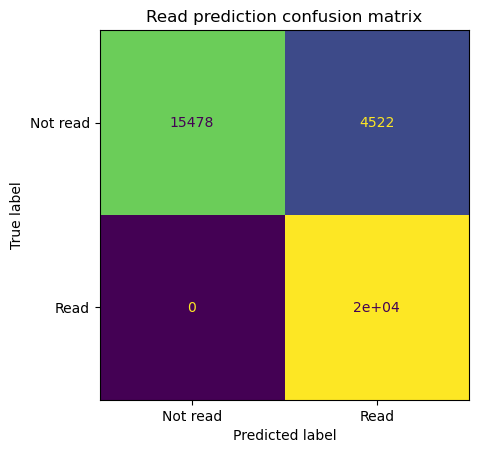

In [319]:
# Build final model with all training data using best parameters
ratingsTrain_final = allRatings
ratingsPerUser_final, ratingsPerItem_final, userBooks_final, bookUsers_final = build_data_structures(ratingsTrain_final)
bookCount_final, userCount_final = compute_counts(ratingsTrain_final)
totalRead_final = len(ratingsTrain_final)

popularBooks_final = build_popular_books(bookCount_final, totalRead_final, popularityThreshold)
activeUsers_final = build_active_users(userCount_final, totalRead_final, activeUsersThreshold)

# Create a validation set for confusion matrix (using last fold's validation data)
val_start = 9 * foldSize
ratingsValid_final = allRatings[val_start:]
validations_final = create_validation_set(ratingsValid_final, userBooks_final)
validation_pairs_final = [(u, b) for u, b, _ in validations_final]
validation_labels_final = [label for _, _, label in validations_final]

# Make predictions with best parameters
y_pred = [predictRead(u, b, userBooks_final, bookUsers_final, 
                     popularBooks_final, activeUsers_final, maxSimThreshold) 
         for u, b in tqdm(validation_pairs_final, desc="Evaluating read predictions")]

cm = confusion_matrix(validation_labels_final, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["Not read", "Read"])
disp.plot(colorbar=False)
plt.title("Read prediction confusion matrix")
accuracy = accuracy_score(validation_labels_final, y_pred)
print(f"Accuracy: {accuracy:.4f}")
plt.show()

In [320]:
# Generate final predictions using the best approach
# Use the final model built in Cell 9 with best parameters
predictions = open("predictions_Read.csv", "w")
for l in tqdm(open("pairs_Read.csv"), desc="Writing read predictions"):
    if l.startswith("userID"):
        predictions.write(l)
        continue
    u, b = l.strip().split(",")
    pred = predictRead(u, b, userBooks_final, bookUsers_final, 
                      popularBooks_final, activeUsers_final, maxSimThreshold)
    predictions.write(f"{u},{b},{pred}\n")
predictions.close()

Writing read predictions: 20001it [00:01, 16448.47it/s]
